In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [58]:
#First, lets make some synthetic data!
rng = np.random.default_rng(42)
X = rng.uniform(0, 10, 50)
y = 3 * X + 7 + rng.normal(0, 3, 50) #This is noise that we add on top of the model

Text(0.5, 1.0, 'Ground Truth Simulated Data')

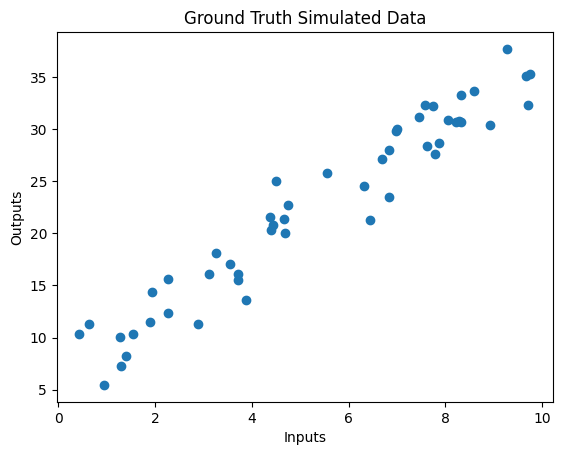

In [35]:
plt.scatter(X, y)
plt.xlabel("Inputs")
plt.ylabel("Outputs")
plt.title("Ground Truth Simulated Data")

### What if we don't have access to the generating model and want to estimate it from data?

In [9]:
def predict(X, w, b):
    return w * X + b

def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

# Gradient Descent 


**Model:** $\hat{y} = wx + b$

**Loss (MSE):** how wrong the line is, on average
$$L(w, b) = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2$$

**Goal:** find the $w$ and $b$ that make $L$ as small as possible.

### Step 1: Compute the gradients

The gradient says which direction makes the loss go **up**, and how steeply.
$$\frac{\partial L}{\partial w} = \frac{2}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)\,x_i
\qquad
\frac{\partial L}{\partial b} = \frac{2}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)$$

```python
err = y_hat - y
dw = 2 * np.mean(err * X)
db = 2 * np.mean(err)
```

### Step 2: Step downhill

Move the parameters a small step in the **opposite** direction of the gradient:
$$w \leftarrow w - \eta\,\frac{\partial L}{\partial w}
\qquad
b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$$

```python
w -= lr * dw
b -= lr * db
```

$\eta$ (`lr`) is the **learning rate**, which controls the step size:
- too small: slow to converge
- too large: overshoots and can diverge

### Step 3: Repeat

Each loop iteration recomputes the predictions, the gradients, and the update.
The loss shrinks every step until $w$ and $b$ settle at the best-fit line.

In [53]:
w, b, lr = 0.0, 0.0, 0.01 #Init params and LR

history = []

for step in range(1000):
    y_hat = predict(X, w, b)
    err = y_hat - y
    dw = 2 * np.mean(err * X)
    db = 2 * np.mean(err)
    w -= lr * dw
    b -= lr * db
    history.append((w, b, mse(y, y_hat)))

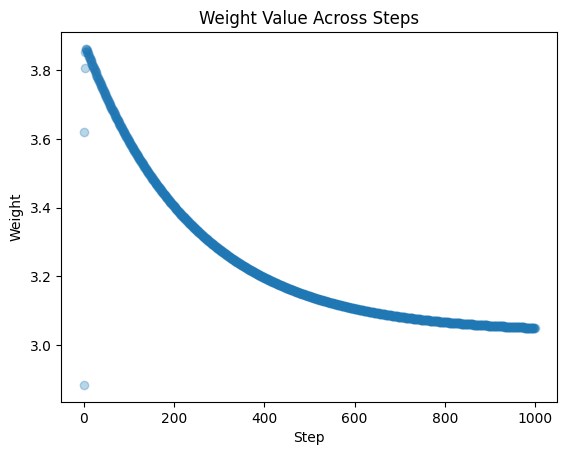

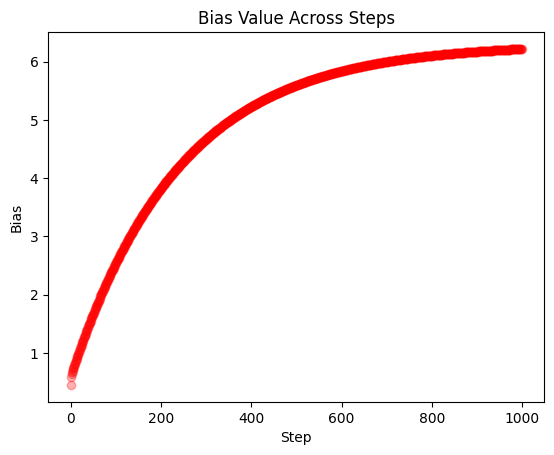

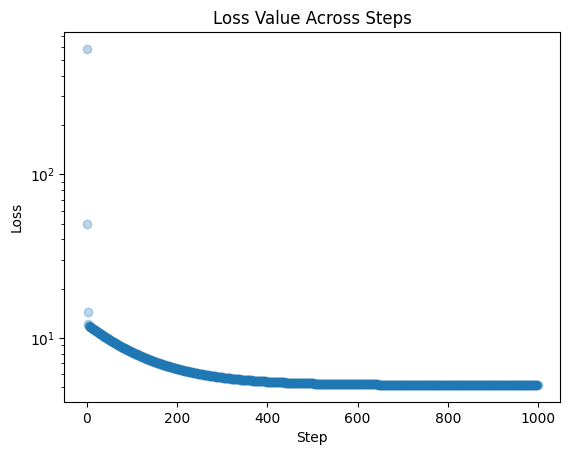

In [56]:
ws, bs , losses = map(np.array, zip(*history))

plt.scatter(range(1000), list(ws), alpha =0.3)
plt.xlabel("Step"); plt.ylabel("Weight"), plt.title("Weight Value Across Steps")
plt.show()


plt.scatter(range(1000), list(bs), alpha =0.3, c = 'r')
plt.xlabel("Step"); plt.ylabel("Bias"), plt.title("Bias Value Across Steps")
plt.show()



plt.scatter(range(1000), list(losses), alpha =0.3)
plt.xlabel("Step"); plt.ylabel("Loss"), plt.title("Loss Value Across Steps"); plt.yscale('log')
plt.show()


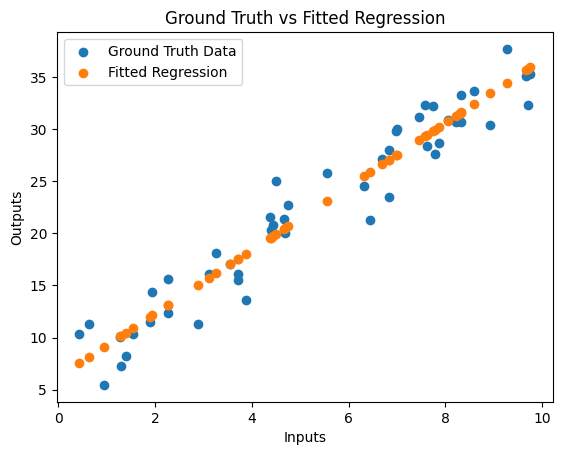

In [66]:
plt.scatter(X, y, label = "Ground Truth Data")
plt.scatter(X, ws[-1]*X + bs[-1], label = "Fitted Regression")
plt.xlabel("Inputs"); plt.ylabel("Outputs"); plt.title("Ground Truth vs Fitted Regression")
plt.legend(); plt.show()

## Deriving the Closed Form

> **Note:** A closed-form solution exists here because the model is linear in its parameters and the loss (MSE) is quadratic, so setting the gradient to zero gives a *linear* system we can solve directly. Change either one (e.g. a neural network, or absolute-error loss) and there's generally no closed form, so we're back to iterative methods like gradient descent.

Instead of stepping downhill, we can solve for the minimum **directly**: set the gradient to zero and solve.

### Set up in matrix form

Stack a column of ones next to $X$ so the bias (intercept) gets absorbed into the parameters:

$$
A = \begin{bmatrix} x_1 & 1 \\ x_2 & 1 \\ \vdots & \vdots \\ x_n & 1 \end{bmatrix},
\qquad
\theta = \begin{bmatrix} w \\ b \end{bmatrix},
\qquad
\hat{y} = A\theta
$$

You need the column of 1's because it gets multiplied with $b$ in matrix form!

**Loss (MSE):**
$$L(\theta) = \frac{1}{n}\,\lVert A\theta - y \rVert^2 = \frac{1}{n}(A\theta - y)^\top(A\theta - y)$$

### Step 1: Expand

$$L(\theta) = \frac{1}{n}\left(\theta^\top A^\top A\,\theta \;-\; 2\,\theta^\top A^\top y \;+\; y^\top y\right)$$

### Step 2: Take the gradient

$$\nabla_\theta L = \frac{1}{n}\left(2A^\top A\,\theta - 2A^\top y\right)$$

### Step 3: Set it to zero

At the minimum the gradient vanishes:
$$A^\top A\,\theta = A^\top y$$

These are the **normal equations**.

### Step 4: Solve

$$\boxed{\theta^* = (A^\top A)^{-1} A^\top y}$$

This works as long as $A^\top A$ is invertible. Since $L$ is a convex quadratic, this point is the **global** minimum.

### Bonus: the scalar version

For a single feature, the normal equations simplify to the formulas from intro stats:

$$w^* = \frac{\sum_i (x_i - \bar{x})(y_i - \bar{y})}{\sum_i (x_i - \bar{x})^2} = \frac{\text{Cov}(x, y)}{\text{Var}(x)},
\qquad
b^* = \bar{y} - w^*\bar{x}$$

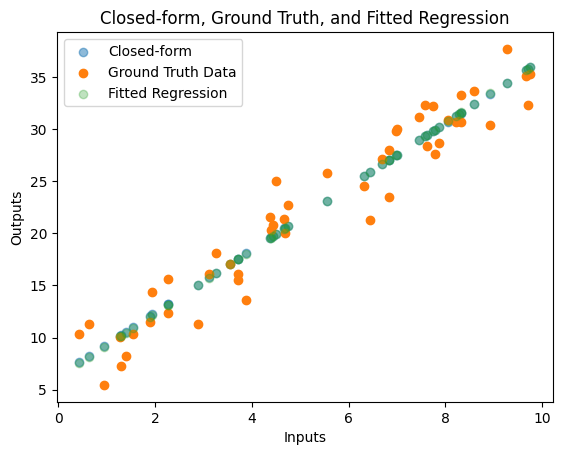

In [74]:
A = np.c_[X, np.ones_like(X)]                
w_cf, b_cf = np.linalg.lstsq(A, y, rcond=None)[0] 

plt.scatter(X, w_cf*X + b_cf, label = "Closed-form", alpha = 0.5)
plt.scatter(X, y, label = "Ground Truth Data")
plt.scatter(X, ws[-1]*X + bs[-1], label = "Fitted Regression", alpha = 0.3)
plt.xlabel("Inputs"); plt.ylabel("Outputs"); plt.title("Closed-form, Ground Truth, and Fitted Regression")
plt.legend(); plt.show()